Figure 7

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec
import pandas as pd
import sys
import os
import numpy as np
import seaborn as sns
sys.path.append(os.path.abspath("/code"))  # Add the root of your package
from bg_spatial_plots.coordinate_transforms import get_annotation_coords
from bg_spatial_plots.figure_utils import add_scalebar, plot_spatial_gene_expression, plot_section_montage
from bg_spatial_plots.constants_color_palettes import CURRENT_COLOR_DICT_OF_DICTS
from bg_spatial_plots.data_utils import load_anndata_obs, calculate_group_proportions, NEURON_NEIGHBORHOODS
from bg_spatial_plots.plot_spatial_histograms import calculate_2D_histogram, plot_2D_histogram, plot_radial_summary
from bg_spatial_plots.utils import GROUP_SHORT_NAMES
from bg_spatial_plots.plot_spatial_gene_expression import multi_species_dotplot
%matplotlib inline


In [3]:
group_color_dict = CURRENT_COLOR_DICT_OF_DICTS['Group']
save_figs=False
dpi=600

In [4]:
mac_file = '/data/cirro_files_hmba_macaque_20260811/hmba_release_format_macaque_cirro_h5ad_20260716_newnames_20260811.h5ad'
mac_ad = load_anndata_obs(mac_file, data_structure='adata', qc=True, subset={'Neighborhood': NEURON_NEIGHBORHOODS})
mac_transform = '/data/macaque_annotations'

In [5]:
marm_file = '/data/cirro_files_hmba_marmoset_CJ23.56.004_BG_revisions_20260811/marmoset-Xenium-CJ23.56.004-Tank_BG_release_format_20260811_neurons.h5ad'
marm_ad = load_anndata_obs(marm_file, data_structure='adata', qc=True, subset={'Neighborhood': NEURON_NEIGHBORHOODS})
marm_transform = '/data/marmoset_BG_manual_annotations_for_rotation'

In [6]:
human_file = '/data/cirro_files_hmba_human_20260811/hmba_release_format_human_cirro_h5ad_20260716_newnames_20260811.h5ad'
human_ad = load_anndata_obs(human_file, data_structure='adata', qc=True, species='human', subset={'Neighborhood': NEURON_NEIGHBORHOODS})
human_transform = '/data/human_annotations'

In [7]:
gpe_groups = ['GPe MEIS2-SOX6 GABA',
    'GPe SOX6-CTXND1 GABA']
gpi_groups = ['GPi Core GABA',
    'GPi Shell GABA-Glut']
all_gp_groups = gpe_groups + gpi_groups

mac_gp = mac_ad[mac_ad.obs['Group'].isin(all_gp_groups)]
gp_mask = mac_gp.obs['GPe'] | mac_gp.obs['GPi']
mac_gp = mac_gp[gp_mask]
mac_gpe = mac_gp[mac_gp.obs['GPe']]
mac_gpe = mac_gpe[mac_gpe.obs['Group'].isin(gpe_groups)]
mac_gpi = mac_gp[mac_gp.obs['GPi']]
mac_gpi = mac_gpi[mac_gpi.obs['Group'].isin(gpi_groups)]

marm_gp = marm_ad[marm_ad.obs['Group'].isin(all_gp_groups)]
gp_mask = marm_gp.obs['GPe'] | marm_gp.obs['GPi']
marm_gp = marm_gp[gp_mask]
marm_gpe = marm_gp[marm_gp.obs['GPe']]
marm_gpe = marm_gpe[marm_gpe.obs['Group'].isin(gpe_groups)]
marm_gpi = marm_gp[marm_gp.obs['GPi']]
marm_gpi = marm_gpi[marm_gpi.obs['Group'].isin(gpi_groups)]

human_gp = human_ad[human_ad.obs['Group'].isin(all_gp_groups)]
gp_mask = human_gp.obs['GPe'] | human_gp.obs['GPi']
human_gp = human_gp[gp_mask]
human_gpe = human_gp[human_gp.obs['GPe']]
human_gpe = human_gpe[human_gpe.obs['Group'].isin(gpe_groups)]
human_gpi = human_gp[human_gp.obs['GPi']]
human_gpi = human_gpi[human_gpi.obs['Group'].isin(gpi_groups)]

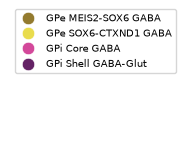

In [8]:
fig, ax = plt.subplots(figsize=(2,1))

dummy_df = pd.DataFrame(all_gp_groups, columns=['Group'])
sns.scatterplot(data=dummy_df, hue='Group', y=dummy_df.index, hue_order=all_gp_groups, palette=group_color_dict, ax=ax)
ax.set_axis_off()
ax.legend(markerscale=1.5, fontsize=7, bbox_to_anchor=(0, 1), ncol=1, loc='lower left', ncols=1)
plt.show()

if save_figs:
    fig.savefig(f'/results/gp_group_legend.png', dpi=dpi, bbox_inches='tight', transparent=False)
    fig.savefig(f'/results/gp_group_legend.svg', bbox_inches='tight', transparent=False)

A. Section montages per species

In [9]:
# find sections that have the GP manual annotation
z_gp_marm = sorted(marm_ad.obs[marm_ad.obs['GPe'] | marm_ad.obs['GPi']]['z_order'].unique())  
# manually trimming 
z_gp_marm = z_gp_marm[1:9]
marm_obs_gp = marm_ad.obs[(marm_ad.obs['z_order'].isin(z_gp_marm)) & (marm_ad.obs['Group'].isin(all_gp_groups))].copy()

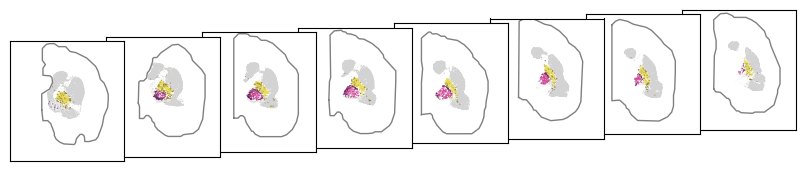

In [10]:
bg_kwargs = {'legend': False, 'color': 'lightgrey', 'rasterized': True, 'edgecolor': None, 's':0.1, 'alpha':0.3}
fg_kwargs = {
    'legend': False, 'hue': 'Group', 'palette': group_color_dict, 
    'rasterized': True, 'edgecolor': None, 's':0.5, 'alpha':0.8
}
hem_outlines_path = '/data/marmoset_hmba_bg_spatial_hemisphere_outlines'
scalebar_params = {'size':10000, 'label':'', 'offset': (0.1, 0.05),} # 'label': '1 cm', 'label_spacing':0.2}
figA_marm_montage = plot_section_montage(
    marm_obs_gp, 
    'x_rotated', 'y_rotated', 
    fg_kwargs, 
    bg_kwargs, 
    ncols=int(np.ceil(len(z_gp_marm))),  
    v_overlap=-0.02, 
    h_overlap=0.02, 
    stagger=0.015,
    flip_y=False,
    zoom_radius=6500, 
    hemisphere_outlines=hem_outlines_path,  
    show_region_circles=False,
    extra_bg_obs=marm_ad.obs,
    extra_bg_kwargs=bg_kwargs,
)

if save_figs:
    figA_marm_montage.savefig(f'/results/marm_montage_gp.png', dpi=dpi, bbox_inches='tight', transparent=False)
    figA_marm_montage.savefig(f'/results/marm_montage_gp.svg', bbox_inches='tight', transparent=False)

In [11]:
# get zplanes, focus on just GPi
z_gp_marm = sorted(marm_ad.obs[marm_ad.obs['GPe'] | marm_ad.obs['GPi']]['z_order'].unique())  
z_gp_marm = z_gp_marm[1:9]

z_gp_mac = sorted(mac_ad.obs[mac_ad.obs['GPe'] | mac_ad.obs['GPi']]['z_order'].unique())
z_gp_mac = z_gp_mac[2:4] + z_gp_mac[5:8]

z_gp_human = sorted(human_ad.obs[human_ad.obs['GPe'] | human_ad.obs['GPi']]['z_order'].unique())  
z_gp_human = z_gp_human[2:]

In [12]:
species_params = {'marmoset': 
            {'adata': marm_ad, 
            'annotations': marm_transform,
            'rotate_midline': True,
            'scale_factor': 1,
             'z_plane': {0:22, 1:23, 2:25},
             'bin_size': 100,
             'xy_cols': ['x_rotated', 'y_rotated'],
             'invert_y': False,
             'bgkwargs': {'s': 1, 'alpha':0.4, 'rasterized':True},
             'fgkwargs': {'s': 5, 'rasterized':True},
            }, 
            'macaque': 
            {'adata': mac_ad, 
            'annotations': mac_transform,
            'rotate_midline': False,
            'scale_factor': 20,
             'z_plane': {1:15, 2:19},
             'bin_size': 200,
             'xy_cols': ['x_slab_um', 'y_slab_um'],
             'invert_y': True,
             'bgkwargs': {'s': 1, 'alpha':0.4, 'rasterized':True},
             'fgkwargs': {'s': 3, 'rasterized':True},
            }, 
            'human': 
            {'adata': human_ad, 
            'annotations': human_transform,
            'rotate_midline': False,
            'scale_factor': 20,
             'z_plane': {2:12},
             'bin_size': 350,
             'xy_cols': ['x_slab_um', 'y_slab_um'],
             'invert_y': True,
             'bgkwargs': {'s': 1, 'alpha':0.4, 'rasterized':True},
             'fgkwargs': {'s': 8, 'rasterized':True},
            }, 
}

no GPi feature for section 1386591529


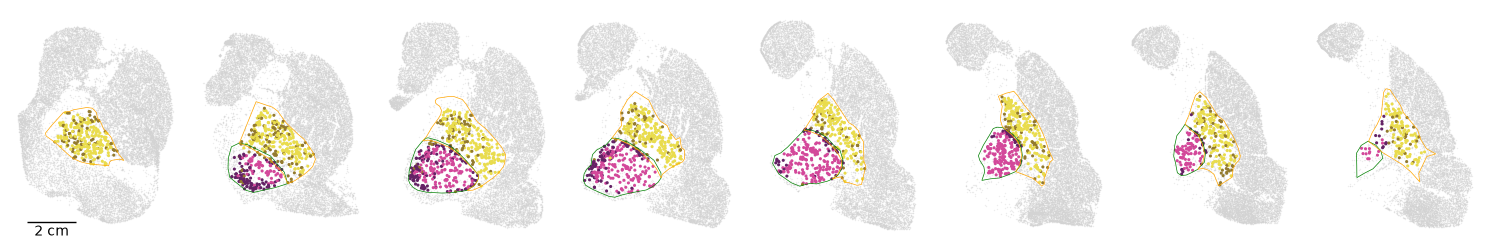

In [13]:
fig, ax = plt.subplots(1, len(z_gp_marm), figsize=(15, 5))
params = species_params['marmoset']
for i, z in enumerate(z_gp_marm):
    data = params['adata'].obs
    x, y = params['xy_cols']
    bg = data[data['z_order']==z]
    gp = bg[bg['Group'].isin(all_gp_groups)]
    gp = gp[(gp['GPi']) | (gp['GPe'])]
    sns.scatterplot(data=bg, x=x, y=y, color='lightgrey', linewidth=0, ax=ax[i], **params['bgkwargs'])
    sns.scatterplot(data=gp, x=x, y=y, hue='Group', palette=group_color_dict, linewidth=0, ax=ax[i], legend=False, **params['fgkwargs'])
    anno_id = bg['brain_section_barcode'].unique()[0]   

    _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPi', ax=ax[i], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                scale_factor=params['scale_factor'], plot_args={'color': 'green', 'linewidth':0.5})
    _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPe', ax=ax[i], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                scale_factor=params['scale_factor'], plot_args={'color': 'orange', 'linewidth':0.5})
    ax[i].set_aspect('equal')
    ax[i].axis('off')
    if params['invert_y']:
        ax[i].invert_yaxis()

add_scalebar(ax[0], matchx=False, matchy=False, sizex=2000, labelx='2 cm', offset=(0.1, 0.05), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)
plt.tight_layout()
plt.show()

if save_figs:
    fig.savefig('/results/marm_gp.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/marm_gp.svg', dpi=dpi, bbox_inches='tight', transparent=True)

no GPi feature for section zpos-14


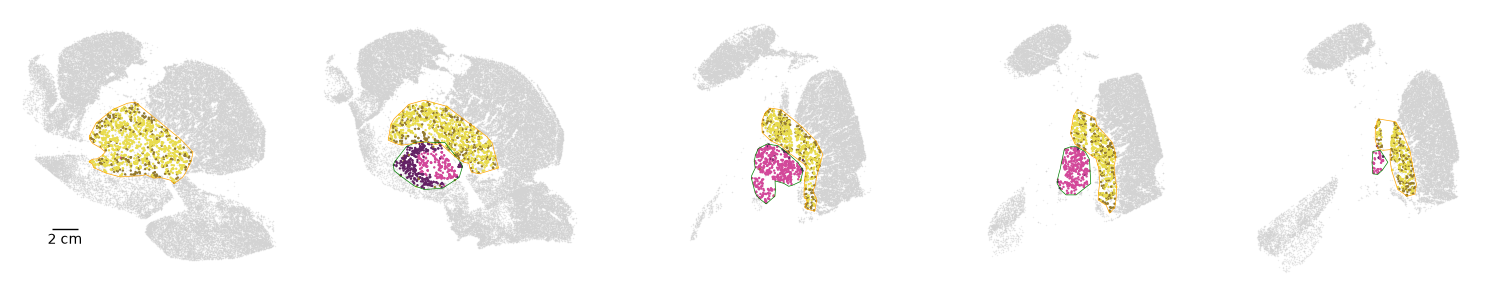

In [14]:
fig, ax = plt.subplots(1, len(z_gp_mac), figsize=(15, 5), sharex=True, sharey=True)
params = species_params['macaque']
for i, z in enumerate(z_gp_mac):
    data = params['adata'].obs
    x, y = params['xy_cols']
    bg = data[data['z_order']==z]
    gp = bg[bg['Group'].isin(all_gp_groups)]
    gp = gp[(gp['GPi']) | (gp['GPe'])]
    sns.scatterplot(data=bg, x=x, y=y, color='lightgrey', linewidth=0, ax=ax[i], **params['bgkwargs'])
    sns.scatterplot(data=gp, x=x, y=y, hue='Group', palette=group_color_dict, linewidth=0, ax=ax[i], legend=False, **params['fgkwargs'])
    anno_id = f'zpos-{z}'   

    _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPi', ax=ax[i], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                scale_factor=params['scale_factor'], plot_args={'color': 'green', 'linewidth':0.5})
    _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPe', ax=ax[i], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                scale_factor=params['scale_factor'], plot_args={'color': 'orange', 'linewidth':0.5})
    ax[i].set_aspect('equal')
    ax[i].axis('off')
    if params['invert_y']:
        ax[i].invert_yaxis()

add_scalebar(ax[0], matchx=False, matchy=False, sizex=2000, labelx='2 cm', offset=(0.15, 0.2), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)
plt.tight_layout()
plt.show()

if save_figs:
    fig.savefig('/results/mac_gp.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/mac_gp.svg', dpi=dpi, bbox_inches='tight', transparent=True)

no GPi feature for section zpos-10


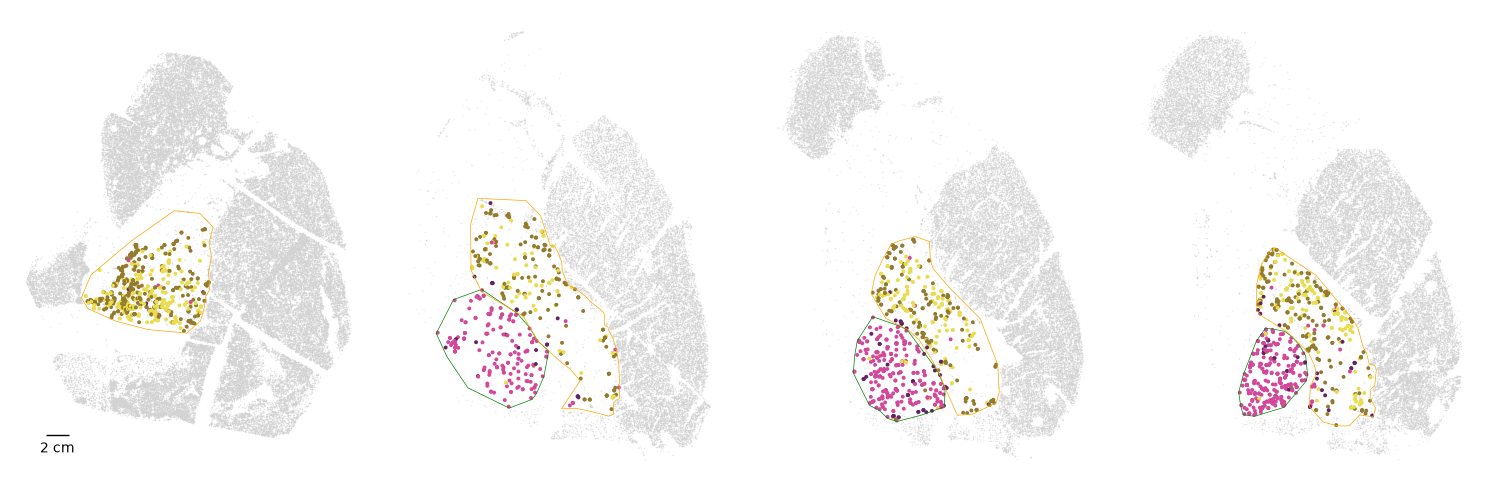

In [15]:
fig, ax = plt.subplots(1, len(z_gp_human), figsize=(15, 5))
params = species_params['human']
for i, z in enumerate(z_gp_human):
    data = params['adata'].obs
    x, y = params['xy_cols']
    bg = data[data['z_order']==z]
    gp = bg[bg['Group'].isin(all_gp_groups)]
    gp = gp[(gp['GPi']) | (gp['GPe'])]
    sns.scatterplot(data=bg, x=x, y=y, color='lightgrey', linewidth=0, ax=ax[i], **params['bgkwargs'])
    sns.scatterplot(data=gp, x=x, y=y, hue='Group', palette=group_color_dict, linewidth=0, ax=ax[i], legend=False, **params['fgkwargs'])
    anno_id = f'zpos-{z}'   

    _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPi', ax=ax[i], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                scale_factor=params['scale_factor'], plot_args={'color': 'green', 'linewidth':0.5})
    _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPe', ax=ax[i], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                scale_factor=params['scale_factor'], plot_args={'color': 'orange', 'linewidth':0.5})
    ax[i].set_aspect('equal')
    ax[i].axis('off')
    if params['invert_y']:
        ax[i].invert_yaxis()

add_scalebar(ax[0], matchx=False, matchy=False, sizex=2000, labelx='2 cm', offset=(0.1, 0.05), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)
plt.tight_layout()
plt.show()

if save_figs:
    fig.savefig('/results/human_gp.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/human_gp.svg', dpi=dpi, bbox_inches='tight', transparent=True)

B. GPi Core-Shell views for each species + radial histograms

/tmp/ipykernel_15307/513989260.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


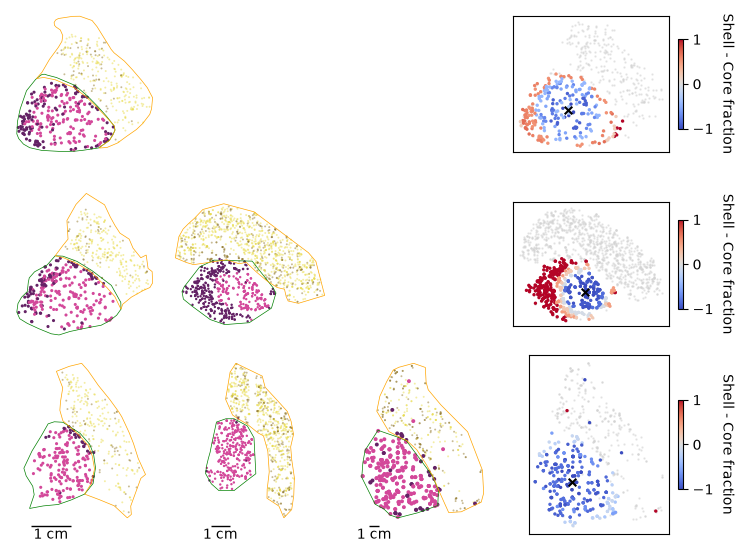

In [16]:
fig, ax = plt.subplots(3, 4, figsize=(9, 7), gridspec_kw={'width_ratios': [1, 1.1, 1.1, 1.3], 'wspace': 0.05, 'hspace': 0.01})

for j, (species, params) in enumerate(species_params.items()):
    data = params['adata'].obs
    x, y = params['xy_cols']
    used_rows = set()
    for i, z in params['z_plane'].items():
        used_rows.add(i)
        bg = data[data['z_order']==z]
        gpe = bg[bg['Group'].isin(gpe_groups)]
        gpe = gpe[gpe['GPe']]
        gpi = bg[bg['Group'].isin(gpi_groups)]
        gpi = gpi[(gpi['GPi']) | (gpi['GPe'])]
        sns.scatterplot(data=gpe, x=x, y=y, hue='Group', palette=group_color_dict, linewidth=0, ax=ax[i, j], legend=False, s=2, alpha=0.5, rasterized =True)
        sns.scatterplot(data=gpi, x=x, y=y, hue='Group', palette=group_color_dict, linewidth=0, ax=ax[i, j], legend=False, **params['fgkwargs'])
        if species == 'marmoset':
            anno_id = bg['brain_section_barcode'].unique()[0]   
        else:
            anno_id = f'zpos-{z}'

        _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPi', ax=ax[i, j], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                    scale_factor=params['scale_factor'], plot_args={'color': 'green', 'linewidth':0.5})
        _ = get_annotation_coords(anno_id, params['annotations'], annotation='GPe', ax=ax[i, j], swap_coords=True, rotate_midline=params['rotate_midline'], 
                                scale_factor=params['scale_factor'], plot_args={'color': 'orange', 'linewidth':0.5})
        ax[i, j].set_aspect('equal')
        ax[i, j].axis('off')
        if params['invert_y']:
            ax[i, j].invert_yaxis()
    for i in range(3):
        if i not in used_rows:
            ax[i, j].remove()
    z_keys = list(params['z_plane'].keys())
    first_z = params['z_plane'][z_keys[0]]
    add_scalebar(ax[i, z_keys[0]], matchx=False, matchy=False, sizex=1000, labelx='1 cm', offset=(0.1, 0), hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1)
    # add core/shell proportion plot
    gp = data[(data['Group'].isin(all_gp_groups))]
    gp = gp[(gp['GPi']) | (gp['GPe'])]
    plot_radial_summary(gp, z_plane=first_z, x=x, y=y,label_key='Group', label_center='GPi Core GABA', label_ring='GPi Shell GABA-Glut', bin_size=params['bin_size'], ax=ax[j, 3])
    if params['invert_y']:
        ax[j, 3].invert_yaxis()

plt.tight_layout()
plt.show()

if save_figs:
    fig.savefig('/results/gpi.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/gpi.svg', dpi=dpi, bbox_inches='tight', transparent=True)

C. Gene expression in GPi Core vs Shell

In [17]:
layer = 'batch_normalized_log1p'

/opt/conda/lib/python3.12/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/opt/conda/lib/python3.12/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/opt/conda/lib/python3.12/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/opt/conda/lib/python3.12/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/opt/conda/lib/python3.12/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatt

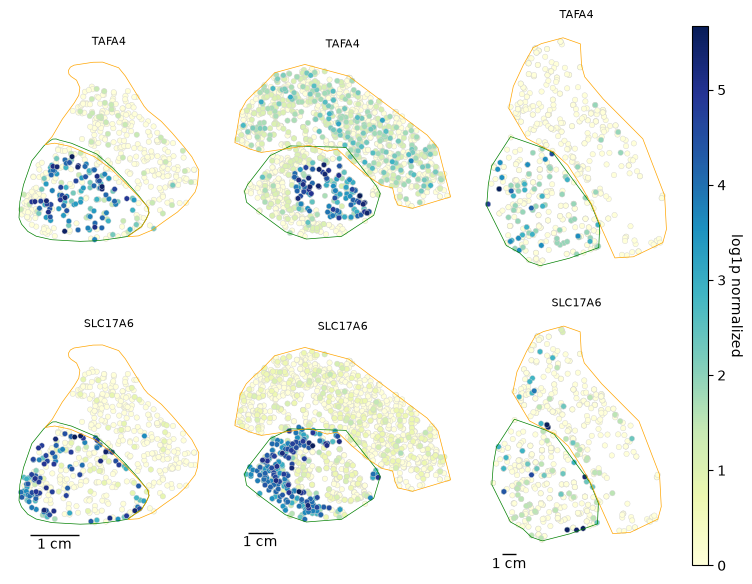

In [18]:
fig = plt.figure(figsize=(9, 7))
gs = gridspec.GridSpec(
    2, 4,
    width_ratios=[1, 1.2, 1, 0.08], 
    hspace=0.15,
    wspace=0.1,
)

ax = np.array([[fig.add_subplot(gs[i, j]) for j in range(3)] for i in range(2)])
cax = fig.add_subplot(gs[:, 3])  
genes = ['TAFA4', 'SLC17A6']

# --- Global vmin/vmax ---
all_vals = []
for species, params in species_params.items():
    data = params['adata']
    z = list(params['z_plane'].values())[0]
    bg = data[data.obs['z_order'] == z]
    gp = bg[bg.obs['Group'].isin(all_gp_groups)]
    gp = gp[(gp.obs['GPi']) | (gp.obs['GPe'])]
    all_vals.append(gp[:, genes].layers[layer].min())
    all_vals.append(gp[:, genes].layers[layer].max())

global_vmin = min(all_vals)
global_vmax = max(all_vals)
norm = mpl.colors.Normalize(vmin=global_vmin, vmax=global_vmax)
sm = plt.cm.ScalarMappable(cmap='YlGnBu', norm=norm)

# --- Plot ---
for j, (species, params) in enumerate(species_params.items()):
    data = params['adata']
    z = list(params['z_plane'].values())[0]
    bg = data[data.obs['z_order'] == z]
    gp = bg[bg.obs['Group'].isin(all_gp_groups)]
    gp = gp[(gp.obs['GPi']) | (gp.obs['GPe'])]
    x, y = params['xy_cols']

    if species == 'marmoset':
        anno_id = bg.obs['brain_section_barcode'].unique()[0]
    else:
        anno_id = f'zpos-{z}'

    for i, gene in enumerate(genes):
        plot_spatial_gene_expression(
            gp, gene, x, y, 'z_order', z, ax=ax[i, j],
            palette='YlGnBu', s=15, legend=False,
            linewidth=0.3, edgecolor='lightgrey',
            layer=layer, rasterized=True,
            vmin=global_vmin, vmax=global_vmax,
        )
        _ = get_annotation_coords(
            anno_id, params['annotations'], annotation='GPi', ax=ax[i, j],
            swap_coords=True, rotate_midline=params['rotate_midline'],
            scale_factor=params['scale_factor'],
            plot_args={'color': 'green', 'linewidth': 0.5}
        )
        _ = get_annotation_coords(
            anno_id, params['annotations'], annotation='GPe', ax=ax[i, j],
            swap_coords=True, rotate_midline=params['rotate_midline'],
            scale_factor=params['scale_factor'],
            plot_args={'color': 'orange', 'linewidth': 0.5}
        )

        ax[i, j].set_aspect('equal')
        ax[i, j].axis('off')
        if params['invert_y']:
            ax[i, j].invert_yaxis()
        ax[i, j].set_title(gene, fontsize=8)

    add_scalebar(
        ax[1, j], matchx=False, matchy=False,
        sizex=1000, labelx='1 cm', offset=(0.1, -0.01),
        hidex=True, hidey=True, loc='lower left', fontsize=10, barwidth=1
    )

# --- Single colorbar in its own dedicated axes ---
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label('log1p normalized', rotation=270, labelpad=12, fontsize=10)
cbar.ax.tick_params(labelsize=10)

plt.show()

if save_figs:
    # fig.savefig('/results/gpi_genes.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/gpi_genes.svg', dpi=dpi, bbox_inches='tight', transparent=True)

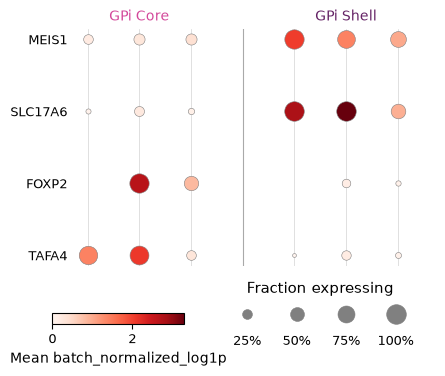

In [19]:
fig, ax = multi_species_dotplot(
    species_adatas=[
        ('Marmoset', marm_gpi),
        ('Macaque',  mac_gpi),
        ('Human',    human_gpi),
    ],
    genes=['TAFA4', 'FOXP2', 'SLC17A6', 'MEIS1'],
    groupby_key='Group',
    layer=layer,
    group_order=gpi_groups,
    group_name_map=GROUP_SHORT_NAMES,
    group_colors=group_color_dict,
    layout='species_cols_T',
)

if save_figs:
    fig.savefig('/results/gpi_gene_dot.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/gpi_gene_dot.svg', dpi=dpi, bbox_inches='tight', transparent=True)

D. GPe spatial histograms and gene expression dot plots

In [20]:
gpe_colors = [group_color_dict[g] for g in gpe_groups]
cmap = LinearSegmentedColormap.from_list('gpe_cmap', [gpe_colors[0], 'white', gpe_colors[1]])

/code/bg_spatial_plots/data_utils.py:172: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_prop = obs_subset.groupby(group_column).size().to_frame('count')


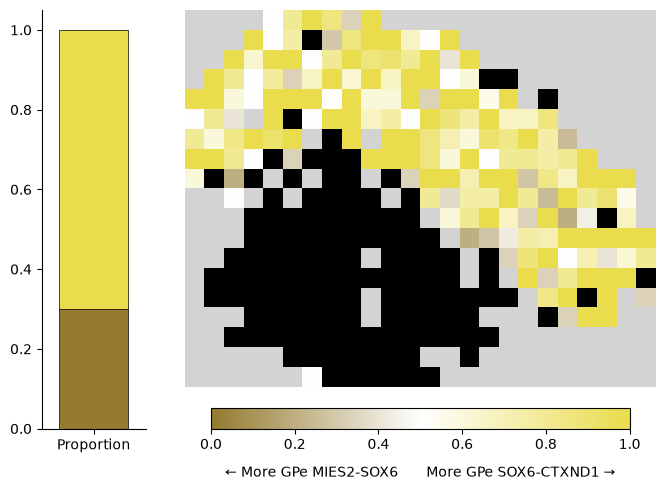

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(7,5), gridspec_kw={'width_ratios': [0.2, 1]})

mac_gpe_prop = calculate_group_proportions(mac_gpe.obs, gpe_groups)
stacked_df = mac_gpe_prop['proportion'].to_frame().T
stacked_df.plot(kind='bar', stacked=True, ax=ax[0], width=1, edgecolor='black', color=gpe_colors, linewidth=0.5, legend=False) 
ax[0].set_xticklabels(['Proportion'], rotation=0, ha='center')
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

gp_z15 = mac_gp[mac_gp.obs['z_order']==15]

H_total, x_edges, y_edges = calculate_2D_histogram(gp_z15, 
                                                    obs_field='Group', 
                                                    category='GPe SOX6-CTXND1 GABA', 
                                                    coords_obsm_key='spatial_grid', 
                                                    binsize=350,
                                                    normalization='proportion')



im = plot_2D_histogram(
    H_total, 
    x_edges, 
    y_edges, 
    ax=ax[1],
    cmap = cmap,
    normalization='proportion',  # Normalize to proportions
    highlight_zero=True,
    show_legend=False,
    show_cbar=False,
    return_im=True
)


cbar = fig.colorbar(im, ax=ax[1], orientation='horizontal', fraction=0.05, pad=0.05, aspect=20)  
cbar.set_label('\u2190 More GPe MIES2-SOX6       More GPe SOX6-CTXND1 \u2192', labelpad=10, fontsize=10)

plt.tight_layout()
plt.show()

if save_figs:
    fig.savefig('/results/mac_gpe_prop.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/mac_gpe_prop.svg', dpi=dpi, bbox_inches='tight', transparent=True)

/code/bg_spatial_plots/data_utils.py:172: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_prop = obs_subset.groupby(group_column).size().to_frame('count')


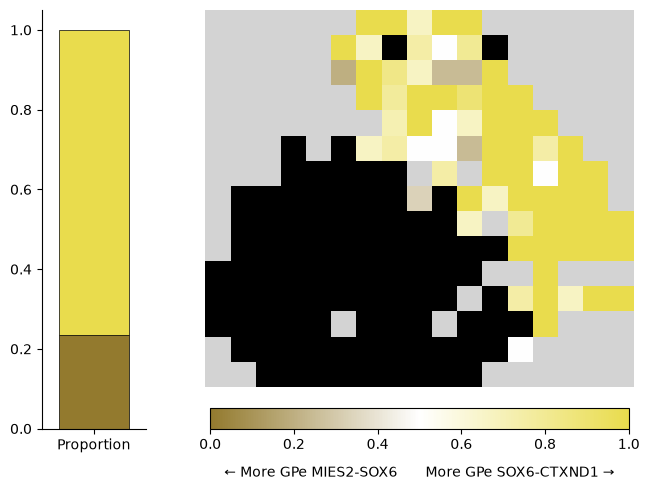

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(7,5), gridspec_kw={'width_ratios': [0.2, 1]})

marm_gpe_prop = calculate_group_proportions(marm_gpe.obs, gpe_groups)
stacked_df = marm_gpe_prop['proportion'].to_frame().T
stacked_df.plot(kind='bar', stacked=True, ax=ax[0], width=1, edgecolor='black', color=gpe_colors, linewidth=0.5, legend=False) 
ax[0].set_xticklabels(['Proportion'], rotation=0, ha='center')
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

gp_z22 = marm_gp[marm_gp.obs['z_order']==22]

H_total, x_edges, y_edges = calculate_2D_histogram(gp_z22, 
                                                    obs_field='Group', 
                                                    category='GPe SOX6-CTXND1 GABA', 
                                                    coords_obsm_key='spatial_cirro_grid_6col', 
                                                    binsize=200,
                                                    normalization='proportion')

im = plot_2D_histogram(
    H_total, 
    x_edges, 
    y_edges, 
    ax=ax[1],
    cmap = cmap,
    normalization='proportion',  # Normalize to proportions
    highlight_zero=True,
    show_legend=False,
    show_cbar=False,
    return_im=True
)

cbar = fig.colorbar(im, ax=ax[1], orientation='horizontal', fraction=0.05, pad=0.05, aspect=20)  
cbar.set_label('\u2190 More GPe MIES2-SOX6       More GPe SOX6-CTXND1 \u2192', labelpad=10, fontsize=10)

plt.tight_layout()
plt.show()

if save_figs:
    fig.savefig('/results/marm_gpe_prop.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/marm_gpe_prop.svg', dpi=dpi, bbox_inches='tight', transparent=True)

/code/bg_spatial_plots/data_utils.py:172: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_prop = obs_subset.groupby(group_column).size().to_frame('count')


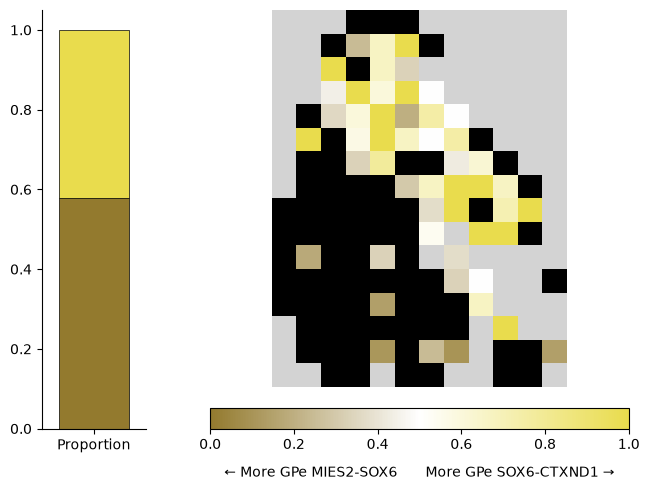

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(7,5), gridspec_kw={'width_ratios': [0.2, 1]})

human_gpe_prop = calculate_group_proportions(human_gpe.obs, gpe_groups)
stacked_df = human_gpe_prop['proportion'].to_frame().T
stacked_df.plot(kind='bar', stacked=True, ax=ax[0], width=1, edgecolor='black', color=gpe_colors, linewidth=0.5, legend=False) 
ax[0].set_xticklabels(['Proportion'], rotation=0, ha='center')
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

gp_z12 = human_gp[human_gp.obs['z_order']==12]

H_total, x_edges, y_edges = calculate_2D_histogram(gp_z12, 
                                                    obs_field='Group', 
                                                    category='GPe SOX6-CTXND1 GABA', 
                                                    coords_obsm_key='spatial_grid', 
                                                    binsize=900,
                                                    normalization='proportion')

im = plot_2D_histogram(
    H_total, 
    x_edges, 
    y_edges, 
    ax=ax[1],
    cmap = cmap,
    normalization='proportion',  # Normalize to proportions
    highlight_zero=True,
    show_legend=False,
    show_cbar=False,
    return_im=True
)

cbar = fig.colorbar(im, ax=ax[1], orientation='horizontal', fraction=0.05, pad=0.05, aspect=20)  
cbar.set_label('\u2190 More GPe MIES2-SOX6       More GPe SOX6-CTXND1 \u2192', labelpad=10, fontsize=10)

plt.tight_layout()
plt.show()

if save_figs:
    fig.savefig('/results/human_gpe_prop.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/human_gpe_prop.svg', dpi=dpi, bbox_inches='tight', transparent=True)

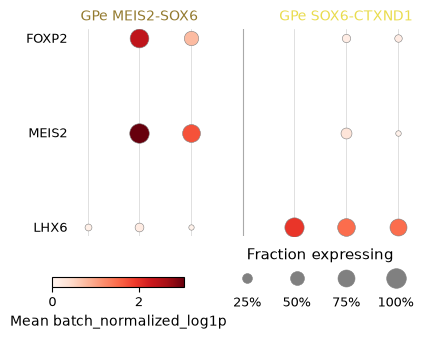

In [24]:
fig, ax = multi_species_dotplot(
    species_adatas=[
        ('Marmoset', marm_gpe),
        ('Macaque',  mac_gpe),
        ('Human',    human_gpe),
    ],
    genes=['LHX6', 'MEIS2', 'FOXP2'],
    groupby_key='Group',
    layer=layer,
    group_order=gpe_groups,
    group_name_map=GROUP_SHORT_NAMES,
    group_colors=group_color_dict,
    layout='species_cols_T',
)
if save_figs:
    fig.savefig('/results/gpe_gene_dot.png', dpi=dpi, bbox_inches='tight', transparent=True)
    fig.savefig('/results/gpe_gene_dot.svg', dpi=dpi, bbox_inches='tight', transparent=True)